# Indian Rainfall Prediction - HackSphere, Aayam XI (v2)

Predict `rainfall_next_day_mm` for every row of `test.csv`. Metric: RMSE. Only the provided data is used.

What v2 adds over v1:
- More features: days since last rain, neighbours 2 days back, state-wide and all-India rain today, neighbours' pressure change, rain anomaly.
- Several models blended together: LightGBM (squared error), LightGBM (Tweedie), CatBoost, and a two-stage "will it rain x how much" model.
- Validation on **two** years (2022 and 2023), so the choices hold up across different monsoons.
- Blend weights and a final scale factor are chosen on validation.
- An error-analysis section.

Key facts about the data:
- Train is 2015-2023 and test is Jan 2024 - Feb 2025, so this is forecasting the future. Validation always trains on the past and tests on a later year.
- In test, each station appears only **every second day**. Every station-level lookup uses even offsets (0, 2, 4, ... days back), which exist in both train and test.

In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import BallTree
from scipy.optimize import nnls

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)

DATA_DIR = "data"
TARGET = "rainfall_next_day_mm"
SEEDS = [42, 7, 2024]          # seeds averaged for the final models
VAL_YEARS = [2022, 2023]       # each year is validated with a model trained on all earlier years

# Uses the same station's next test row (2 days later). Only provided data, but it is
# information from after the prediction date. Keep False unless the organisers confirm it is fine.
USE_FUTURE_ROW = False

# set FORCE_SKLEARN=1 in the environment to run with scikit-learn models only
FORCE_SKLEARN = os.environ.get("FORCE_SKLEARN") == "1"
try:
    import lightgbm as lgb
    HAS_LGB = not FORCE_SKLEARN
except ImportError:
    HAS_LGB = False
try:
    from catboost import CatBoostRegressor
    HAS_CB = not FORCE_SKLEARN
except ImportError:
    HAS_CB = False
print("LightGBM:", HAS_LGB, "| CatBoost:", HAS_CB)

LightGBM: True | CatBoost: True


## 1. Load data

In [2]:
train = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
test = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))
sub = pd.read_csv(os.path.join(DATA_DIR, "sample_submission.csv"))
for df in (train, test):
    df["date"] = pd.to_datetime(df["date"])
print(train.shape, test.shape)
print("train:", train.date.min().date(), "->", train.date.max().date(),
      "| test:", test.date.min().date(), "->", test.date.max().date())

(546703, 16) (81803, 16)
train: 2015-01-01 -> 2023-12-30 | test: 2024-01-01 -> 2025-02-08


## 2. EDA

air_pressure         0.171
wind_speed           0.153
max_temp             0.061
rainfall_today_mm    0.037
min_temp             0.025
date                 0.000
dtype: float64
count    546703.00
mean          5.64
std          15.07
min           0.00
50%           0.10
90%          16.10
99%          71.40
max         480.10
Name: rainfall_next_day_mm, dtype: float64
dry share: 0.491


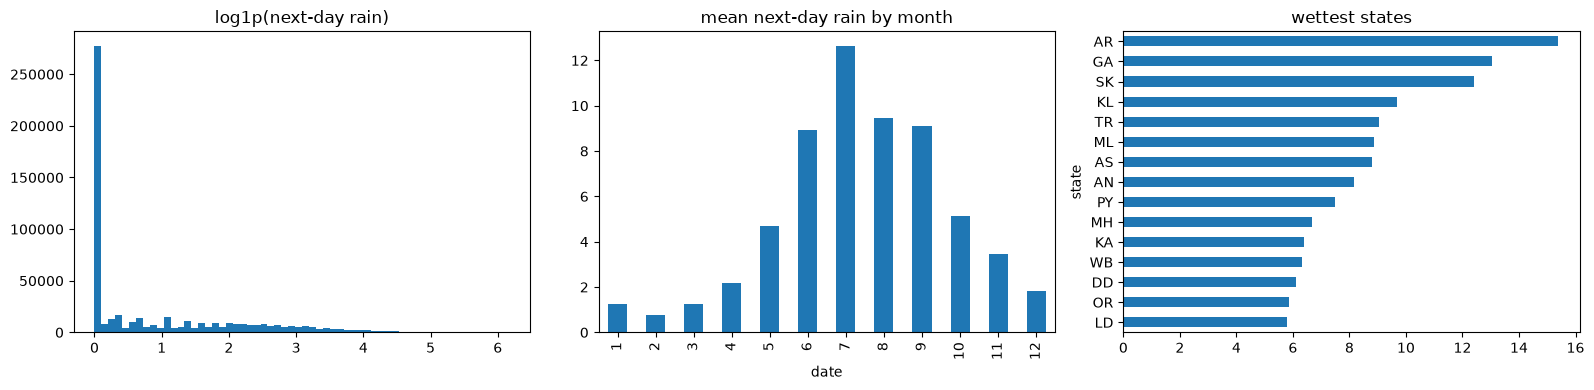

train gap between rows of a station (days): {1.0: 513879, 0.0: 11785, 2.0: 3713}
test gap between rows of a station (days): {2.0: 79053, 0.0: 1593, 4.0: 322}


In [3]:
print(train.isna().mean().sort_values(ascending=False).head(6).round(3))
print(train[TARGET].describe(percentiles=[.5, .9, .99]).round(2))
print("dry share:", (train[TARGET] == 0).mean().round(3))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].hist(np.log1p(train[TARGET]), bins=60); ax[0].set_title("log1p(next-day rain)")
train.groupby(train.date.dt.month)[TARGET].mean().plot.bar(ax=ax[1], title="mean next-day rain by month")
train.groupby("state")[TARGET].mean().sort_values().tail(15).plot.barh(ax=ax[2], title="wettest states")
plt.tight_layout(); plt.show()

for name, df in [("train", train), ("test", test)]:
    gaps = df.sort_values("date").groupby("station_name")["date"].diff().dt.days
    print(name, "gap between rows of a station (days):", gaps.value_counts().head(3).to_dict())

## 3. Lookup table
One observation per station per day (about 2% of station-days are duplicated, so they are averaged).
All lag and neighbour features are read from this table.

In [4]:
train["is_test"] = 0
test["is_test"] = 1
full = pd.concat([train, test], ignore_index=True, sort=False)

obs = (full.groupby(["station_name", "date"], as_index=False)
           .agg(rain=("rainfall_today_mm", "mean"), avg_temp=("avg_temp", "mean"),
                air_pressure=("air_pressure", "mean"), state=("state", "first"),
                lat=("latitude", "first"), lon=("longitude", "first")))
obs_idx = obs.set_index(["station_name", "date"])

def obs_lookup(col, days, frame):
    key = pd.MultiIndex.from_arrays([frame.station_name, frame.date + pd.Timedelta(days=days)])
    return obs_idx[col].reindex(key).values

obs["pchg2"] = obs.air_pressure - obs_lookup("air_pressure", -2, obs)
obs_idx = obs.set_index(["station_name", "date"])
print(obs.shape)

(615128, 9)


## 4. Features

**4a. Calendar and today's weather**

In [5]:
full["doy"] = full.date.dt.dayofyear
full["month_num"] = full.date.dt.month
full["year"] = full.date.dt.year
full["doy_sin"] = np.sin(2 * np.pi * full.doy / 365.25)
full["doy_cos"] = np.cos(2 * np.pi * full.doy / 365.25)
full["temp_range"] = full.max_temp - full.min_temp
full["rain_today_log"] = np.log1p(full.rainfall_today_mm)
full["rained_today"] = np.where(full.rainfall_today_mm.isna(), np.nan, (full.rainfall_today_mm > 0.1).astype(float))
for c in ["state", "season", "station_name", "district"]:
    full[c + "_cat"] = full[c].astype("category").cat.codes

**4b. Same-station history.** Even offsets only (test has every second day).
`days_since_rain` = how many days back the last wet reading was (0 = today, capped at 16).

In [6]:
for k in (2, 4, 6):
    full[f"rain_lag{k}"] = obs_lookup("rain", -k, full)
full["pressure_chg2"] = full.air_pressure - obs_lookup("air_pressure", -2, full)
full["pressure_chg4"] = full.air_pressure - obs_lookup("air_pressure", -4, full)
full["temp_chg2"] = full.avg_temp - obs_lookup("avg_temp", -2, full)

# days since last wet reading, looking at offsets 0, 2, 4, ..., 14
dsr = np.full(len(full), 16.0)
for k in range(14, -1, -2):
    r = full.rainfall_today_mm.values if k == 0 else obs_lookup("rain", -k, full)
    dsr = np.where(r > 0.1, k, dsr)
full["days_since_rain"] = dsr

# rolling mean of the readings available in the previous 14 days
obs_sorted = obs.sort_values(["station_name", "date"]).set_index("date")
roll = (obs_sorted.groupby("station_name")["rain"]
        .apply(lambda s: s.shift(1).rolling("14D", min_periods=1).mean())
        .reset_index().rename(columns={"rain": "rain_roll14"}))
full = full.merge(roll, on=["station_name", "date"], how="left")

**4c. Neighbouring stations on the same day.** For each date: the 6 nearest other stations within 250 km
(haversine). Inverse-distance-weighted mean rain, max rain, share of wet neighbours, count, nearest distance,
and the neighbours' average 2-day pressure change.

In [7]:
EARTH_KM, K_NEIGH, MAX_KM = 6371.0, 6, 250

def neighbour_feats(day):
    d = day.dropna(subset=["rain"])
    if len(d) < 2:
        return None
    tree = BallTree(np.radians(d[["lat", "lon"]].values), metric="haversine")
    k = min(K_NEIGH + 1, len(d))
    dist, ind = tree.query(np.radians(day[["lat", "lon"]].values), k=k)
    dist = dist * EARTH_KM
    rain = d["rain"].values[ind]
    pchg = d["pchg2"].values[ind]
    names = d["station_name"].to_numpy(dtype=object)
    ok = (names[ind] != day["station_name"].to_numpy(dtype=object)[:, None]) & (dist <= MAX_KM)
    w = np.where(ok, 1.0 / (dist + 10.0), 0.0)
    wsum = w.sum(1)
    any_ok = ok.any(1)
    wp = np.where(ok & ~np.isnan(pchg), w, 0.0)
    return pd.DataFrame({
        "station_name": day["station_name"].values,
        "nb_rain_wmean": np.where(wsum > 0, (w * rain).sum(1) / np.maximum(wsum, 1e-9), np.nan),
        "nb_rain_max": np.where(any_ok, np.where(ok, rain, -1).max(1), np.nan),
        "nb_rain_share": np.where(any_ok, (ok & (rain > 0.1)).sum(1) / np.maximum(ok.sum(1), 1), np.nan),
        "nb_count": ok.sum(1),
        "nb_min_km": np.where(any_ok, np.where(ok, dist, np.inf).min(1), np.nan),
        "nb_pchg2": np.where(wp.sum(1) > 0, (wp * np.nan_to_num(pchg)).sum(1) / np.maximum(wp.sum(1), 1e-9), np.nan),
    })

t0 = time.time()
parts = []
for dt, g in obs.groupby("date"):
    nf = neighbour_feats(g)
    if nf is not None:
        nf["date"] = dt
        parts.append(nf)
nb = pd.concat(parts, ignore_index=True)
full = full.merge(nb, on=["station_name", "date"], how="left")

# neighbours 2 days back
nb_lag = nb[["station_name", "date", "nb_rain_wmean", "nb_rain_max"]].copy()
nb_lag["date"] = nb_lag["date"] + pd.Timedelta(days=2)
full = full.merge(nb_lag.rename(columns={"nb_rain_wmean": "nb_rain_wmean_lag2", "nb_rain_max": "nb_rain_max_lag2"}),
                  on=["station_name", "date"], how="left")
print(f"neighbour features: {time.time() - t0:.0f}s")

neighbour features: 9s


**4d. Regional rain today**: mean and share of wet stations across the whole state and across India.

In [8]:
state_day = obs.groupby(["state", "date"]).agg(state_rain_mean=("rain", "mean"),
                                               state_wet_share=("rain", lambda s: (s > 0.1).mean())).reset_index()
india_day = obs.groupby("date").agg(india_rain_mean=("rain", "mean"),
                                    india_wet_share=("rain", lambda s: (s > 0.1).mean())).reset_index()
full = full.merge(state_day, on=["state", "date"], how="left").merge(india_day, on="date", how="left")

**4e. Future-row features (only used if `USE_FUTURE_ROW = True`).**
The same station's next row in test is 2 days later. Its rain is rain on the day after the target day.

In [9]:
FUTURE_COLS = ["rain_lead2", "pressure_lead2_chg", "nb_rain_wmean_lead2"]
full["rain_lead2"] = obs_lookup("rain", 2, full)
full["pressure_lead2_chg"] = obs_lookup("air_pressure", 2, full) - full.air_pressure
nb_lead = nb[["station_name", "date", "nb_rain_wmean"]].copy()
nb_lead["date"] = nb_lead["date"] - pd.Timedelta(days=2)
full = full.merge(nb_lead.rename(columns={"nb_rain_wmean": "nb_rain_wmean_lead2"}),
                  on=["station_name", "date"], how="left")

**4f. Climatology (target encoding).** Smoothed mean next-day rain and wet probability per station,
station-month and state-month, computed **only from the training part** of each split.
Also `rain_anom`: today's rain minus the station's normal for the month.

In [10]:
def add_climatology(tr, others, prior_n=20):
    g_mean = tr[TARGET].mean()
    wet = (tr[TARGET] > 0.1).astype(float)
    stats = {}
    for key in [("station_name",), ("station_name", "month_num"), ("state", "month_num")]:
        grp = tr.groupby(list(key))
        s = grp[TARGET].agg(["mean", "count"])
        enc = (s["mean"] * s["count"] + g_mean * prior_n) / (s["count"] + prior_n)
        wp = wet.groupby([tr[k] for k in key]).mean()
        stats[key] = (enc, wp)
    out = []
    for f in [tr] + list(others):
        f = f.copy()
        for key, (enc, wp) in stats.items():
            name = "_".join(k.replace("station_name", "stn").replace("month_num", "m") for k in key)
            idx = pd.MultiIndex.from_frame(f[list(key)]) if len(key) > 1 else f[key[0]]
            f[f"clim_{name}"] = enc.reindex(idx).values
            f[f"wetp_{name}"] = wp.reindex(idx).values
        f["rain_anom"] = f.rainfall_today_mm - f.clim_stn_m
        out.append(f)
    return out

In [11]:
BASE_FEATS = [
    "latitude", "longitude", "elevation",
    "avg_temp", "min_temp", "max_temp", "temp_range", "wind_speed", "air_pressure",
    "rainfall_today_mm", "rain_today_log", "rained_today",
    "doy_sin", "doy_cos", "month_num", "state_cat", "season_cat", "station_name_cat",
    "rain_lag2", "rain_lag4", "rain_lag6", "rain_roll14", "days_since_rain",
    "pressure_chg2", "pressure_chg4", "temp_chg2",
    "nb_rain_wmean", "nb_rain_max", "nb_rain_share", "nb_count", "nb_min_km", "nb_pchg2",
    "nb_rain_wmean_lag2", "nb_rain_max_lag2",
    "state_rain_mean", "state_wet_share", "india_rain_mean", "india_wet_share",
    "clim_stn", "wetp_stn", "clim_stn_m", "wetp_stn_m", "clim_state_m", "wetp_state_m", "rain_anom",
]
FEATS = BASE_FEATS + (FUTURE_COLS if USE_FUTURE_ROW else [])
tr_all = full[full.is_test == 0].reset_index(drop=True)
te_all = full[full.is_test == 1].reset_index(drop=True)
print(len(FEATS), "features")

45 features


## 5. Models
| name | what it is | why |
|---|---|---|
| `l2` | gradient boosting, squared error | matches RMSE directly |
| `tweedie` | gradient boosting, Tweedie loss (Poisson in the sklearn fallback) | built for targets with many zeros and a long tail, like rain |
| `cat` | CatBoost, RMSE | a different tree algorithm, so it makes different mistakes; good for blending |
| `twostage` | P(rain > 0.1 mm) x amount on wet days | splits "will it rain" from "how much" |

In [12]:
def lgb_params(seed):
    return dict(n_estimators=5000, learning_rate=0.03, num_leaves=127, min_child_samples=50,
                subsample=0.8, subsample_freq=1, colsample_bytree=0.7, reg_lambda=1.0,
                random_state=seed, verbose=-1, metric="rmse")

def fit_predict(name, Xtr, ytr, Xev, seed=42, n_iter=None, Xva=None, yva=None):
    """Fit one model and predict Xev. If Xva/yva are given, early stopping is used.
    Returns (predictions, number of iterations used)."""
    es = Xva is not None
    if name in ("l2", "tweedie") and HAS_LGB:
        extra = dict(objective="tweedie", tweedie_variance_power=1.3) if name == "tweedie" else {}
        p = lgb_params(seed); p.update(extra)
        if n_iter: p["n_estimators"] = n_iter
        m = lgb.LGBMRegressor(**p)
        if es:
            m.fit(Xtr, ytr, eval_set=[(Xva, yva)],
                  callbacks=[lgb.early_stopping(150, first_metric_only=True, verbose=False)])
            return m.predict(Xev), m.best_iteration_
        m.fit(Xtr, ytr)
        return m.predict(Xev), n_iter
    if name in ("l2", "tweedie"):
        from sklearn.ensemble import HistGradientBoostingRegressor
        m = HistGradientBoostingRegressor(
            loss="poisson" if name == "tweedie" else "squared_error",
            max_iter=n_iter or 500, learning_rate=0.06, max_leaf_nodes=63, min_samples_leaf=50,
            l2_regularization=1.0, random_state=seed)
        m.fit(Xtr, ytr)
        return m.predict(Xev), m.n_iter_
    if name == "cat":
        m = CatBoostRegressor(iterations=n_iter or 3000, learning_rate=0.08, depth=8,
                              loss_function="RMSE", random_seed=seed, verbose=False, thread_count=-1)
        if es:
            m.fit(Xtr, ytr, eval_set=(Xva, yva), early_stopping_rounds=200)
            return m.predict(Xev), m.get_best_iteration()
        m.fit(Xtr, ytr)
        return m.predict(Xev), n_iter
    if name == "twostage":
        wet_tr = ytr > 0.1
        if HAS_LGB:
            clf = lgb.LGBMClassifier(n_estimators=n_iter or 800, learning_rate=0.05, num_leaves=127,
                                     min_child_samples=50, subsample=0.8, subsample_freq=1,
                                     colsample_bytree=0.7, random_state=seed, verbose=-1)
            reg = lgb.LGBMRegressor(**{**lgb_params(seed), "n_estimators": n_iter or 800, "learning_rate": 0.05})
        else:
            from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
            clf = HistGradientBoostingClassifier(max_iter=n_iter or 300, learning_rate=0.08,
                                                 max_leaf_nodes=63, random_state=seed)
            reg = HistGradientBoostingRegressor(max_iter=n_iter or 300, learning_rate=0.08,
                                                max_leaf_nodes=63, random_state=seed)
        clf.fit(Xtr, wet_tr)
        reg.fit(Xtr[wet_tr], ytr[wet_tr])
        return clf.predict_proba(Xev)[:, 1] * np.clip(reg.predict(Xev), 0, None), n_iter
    raise ValueError(name)

MODELS = ["l2", "tweedie"] + (["cat"] if HAS_CB else []) + ["twostage"]
rmse = lambda a, b: float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))
print("models:", MODELS)

models: ['l2', 'tweedie', 'cat', 'twostage']


## 6. Validation on two years
For each year in `VAL_YEARS`: train on everything before it, predict that year
(thinned to every second day per station, like test), and record each model's predictions.

In [13]:
oof = []          # validation predictions from every fold
best_iters = {m: [] for m in MODELS}
for year in VAL_YEARS:
    start = pd.Timestamp(f"{year}-01-01")
    tr = tr_all[tr_all.date < start]
    va = tr_all[(tr_all.date >= start) & (tr_all.date < pd.Timestamp(f"{year + 1}-01-01"))]
    va = va[(va.date - start).dt.days % 2 == 0]
    tr, va = add_climatology(tr, [va])
    res = va[["date", "station_name", "state", "latitude", "longitude", TARGET, "rainfall_today_mm"]].copy()
    res["year"] = year
    for name in MODELS:
        t0 = time.time()
        p, it = fit_predict(name, tr[FEATS], tr[TARGET], va[FEATS], Xva=va[FEATS], yva=va[TARGET])
        res[name] = np.clip(p, 0, None)
        best_iters[name].append(it)
        print(f"{year} {name:9s} RMSE {rmse(va[TARGET], res[name]):.3f}  iters {it}  ({time.time() - t0:.0f}s)")
    oof.append(res)
oof = pd.concat(oof, ignore_index=True)

2022 l2        RMSE 9.518  iters 96  (3s)


2022 tweedie   RMSE 9.538  iters 135  (4s)


2022 cat       RMSE 9.519  iters 229  (9s)


2022 twostage  RMSE 9.834  iters None  (13s)


2023 l2        RMSE 8.888  iters 441  (7s)


2023 tweedie   RMSE 8.915  iters 343  (14s)


2023 cat       RMSE 8.926  iters 465  (30s)


2023 twostage  RMSE 8.953  iters None  (44s)


## 7. Blend and scale
Blend weights are found with non-negative least squares on the validation predictions of both years.
Then one scale factor is tested, because tree models tend to under-predict extreme rain.

In [14]:
X_oof = oof[MODELS].values
w, _ = nnls(X_oof, oof[TARGET].values)
w = w / w.sum()
oof["blend"] = X_oof @ w

scales = np.arange(0.95, 1.16, 0.01)
scale_rmse = [rmse(oof[TARGET], oof.blend * s) for s in scales]
SCALE = float(scales[int(np.argmin(scale_rmse))])
oof["final"] = oof.blend * SCALE

rows = []
for col in ["rainfall_today_mm"] + MODELS + ["blend", "final"]:
    pred = oof[col].fillna(0)
    rows.append({"model": col, **{str(y): rmse(g[TARGET], pred[g.index]) for y, g in oof.groupby("year")},
                 "both": rmse(oof[TARGET], pred)})
summary = pd.DataFrame(rows).set_index("model").round(3)
summary.index = summary.index.str.replace("rainfall_today_mm", "baseline: tomorrow = today")
summary.to_csv("validation_results.csv")
print("blend weights:", dict(zip(MODELS, w.round(3))), "| scale:", round(SCALE, 2))
summary

blend weights: {'l2': np.float64(0.35), 'tweedie': np.float64(0.317), 'cat': np.float64(0.295), 'twostage': np.float64(0.038)} | scale: 1.03


,2022,2023,both
model,,,
baseline: tomorrow = today,11.623,11.309,11.466
l2,9.518,8.888,9.206
tweedie,9.538,8.915,9.230
cat,9.519,8.926,9.225
twostage,9.834,8.953,9.401
blend,9.482,8.866,9.178
final,9.483,8.861,9.175


## 8. Error analysis
Where does the model go wrong? These charts help decide what to work on next.

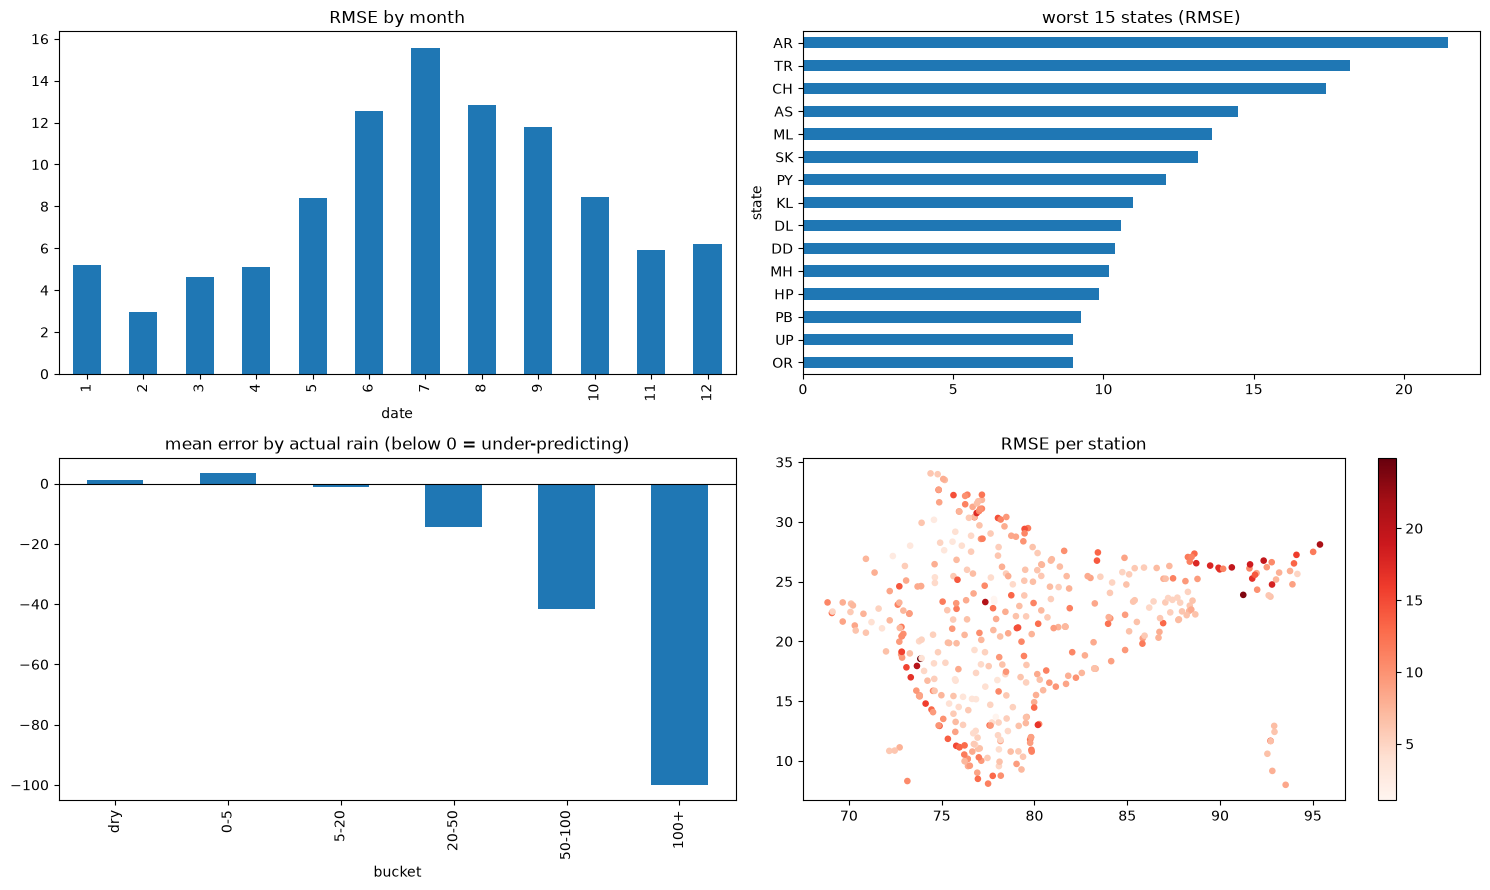

share of total squared error from days with > 50 mm actual rain: 0.566


In [15]:
oof["err"] = oof.final - oof[TARGET]
fig, ax = plt.subplots(2, 2, figsize=(15, 9))

oof.groupby(oof.date.dt.month).apply(lambda g: rmse(g[TARGET], g.final)).plot.bar(ax=ax[0, 0], title="RMSE by month")

st = oof.groupby("state").apply(lambda g: rmse(g[TARGET], g.final)).sort_values()
st.tail(15).plot.barh(ax=ax[0, 1], title="worst 15 states (RMSE)")

bins = [-0.1, 0.1, 5, 20, 50, 100, 1000]
labels = ["dry", "0-5", "5-20", "20-50", "50-100", "100+"]
oof["bucket"] = pd.cut(oof[TARGET], bins=bins, labels=labels)
oof.groupby("bucket")["err"].mean().plot.bar(ax=ax[1, 0], title="mean error by actual rain (below 0 = under-predicting)")
ax[1, 0].axhline(0, color="k", lw=0.8)

stn = oof.groupby("station_name").agg(lat=("latitude", "first"), lon=("longitude", "first"),
                                      rmse=("err", lambda e: np.sqrt((e ** 2).mean())))
sc = ax[1, 1].scatter(stn.lon, stn.lat, c=stn.rmse, cmap="Reds", s=14)
plt.colorbar(sc, ax=ax[1, 1]); ax[1, 1].set_title("RMSE per station")
plt.tight_layout(); plt.show()

print("share of total squared error from days with > 50 mm actual rain:",
      round(((oof.err ** 2)[oof[TARGET] > 50]).sum() / (oof.err ** 2).sum(), 3))

## 9. Final models on all of train, predict test
Each model is retrained on 2015-2023 with the average number of iterations from validation
(+10% for the extra data), averaged over `SEEDS`, then blended with the weights and scale from section 7.

In [16]:
tr_full, te = add_climatology(tr_all, [te_all])
test_preds = {}
for name in MODELS:
    its = [i for i in best_iters[name] if i]
    n_iter = int(np.mean(its) * 1.1) if its else None
    ps = []
    for seed in SEEDS:
        t0 = time.time()
        p, _ = fit_predict(name, tr_full[FEATS], tr_full[TARGET], te[FEATS], seed=seed, n_iter=n_iter)
        ps.append(np.clip(p, 0, None))
        print(f"{name:9s} seed {seed}: {time.time() - t0:.0f}s")
    test_preds[name] = np.mean(ps, axis=0)

te["pred"] = np.clip(np.column_stack([test_preds[m] for m in MODELS]) @ w * SCALE, 0, None)
submission = sub[["id"]].merge(te[["id", "pred"]], on="id", how="left").rename(columns={"pred": TARGET})
assert len(submission) == len(sub) and submission[TARGET].notna().all() and (submission[TARGET] >= 0).all()
submission.to_csv("submission.csv", index=False)
print(submission[TARGET].describe().round(3))

l2        seed 42: 10s


l2        seed 7: 8s


l2        seed 2024: 8s


tweedie   seed 42: 11s


tweedie   seed 7: 9s


tweedie   seed 2024: 6s


... (2 outputs left out)

cat       seed 2024: 14s


twostage  seed 42: 22s


twostage  seed 7: 23s


twostage  seed 2024: 44s
count    81803.000
mean         3.944
std          7.498
min          0.001
25%          0.105
50%          0.701
75%          5.057
max        189.545
Name: rainfall_next_day_mm, dtype: float64


## 10. Experiment log
Write every experiment here with its validation RMSE (both years), and keep a change only if it helps in both.

| # | change | 2022 | 2023 | both | kept? |
|---|---|---|---|---|---|
| 1 | v2 baseline |  |  |  | yes |